# Ocupación diaria · Reto Sprint 12 («Escuchar al cliente») · Equipo 5 Green

- **Equipo**: 5 Green

- **Integrantes**: Cristina, Miguel, Fran, Andri, Anzhela

- **Contexto**: TurisData Canarias

- **Fecha**: 24-25.11.2026
- **scrum master** Miguel, **técnico** Anzela
- **Semilla:** `SEMILLA = 42`
- **Objetivo:** Partir la serie por fecha (sin barajar), calcular un *baseline* («igual que la semana anterior»), comparar al menos dos modelos (`SARIMAX` y modelo con ventana temporal de 7 días), mostrar MAE en la misma tabla, generar la previsión a 7 días y dejar una frase para la dirección de TurisData.

In [ ]:
# ===================== CELDA 1: IMPORTS Y CARGA DE DATOS =====================
import os                                   # Utilidades del sistema operativo (rutas, carpetas)
import numpy as np                          # Cálculo numérico con arrays
import pandas as pd                         # Manejo de tablas (DataFrame) y fechas
import matplotlib.pyplot as plt             # Librería para dibujar gráficos
from sklearn.metrics import mean_absolute_error   # Métrica MAE: media de |real - predicho|
from sklearn.preprocessing import StandardScaler  # Escalador: resta la media y divide por la desviación típica
from sklearn.linear_model import Ridge            # Regresión lineal con regularización L2 (penaliza coeficientes grandes)

SEMILLA = 42                                # Semilla fija para que los resultados sean reproducibles
np.random.seed(SEMILLA)                     # Fija la semilla del generador aleatorio de NumPy

os.makedirs("data", exist_ok=True)          # Crea la carpeta "data" si no existe (sin error si ya existe)
ruta_csv = "data/ocupacion_diaria.csv"      # Ruta donde esperamos encontrar el CSV real de ocupación

if os.path.exists(ruta_csv):                # CASO A: si existe el CSV real, lo cargamos
    df_ocup = pd.read_csv(ruta_csv)         # Lee el CSV en un DataFrame
    # Busca la columna de fecha entre nombres típicos; si no hay ninguna, usa la primera columna
    col_fecha = next((c for c in ["fecha", "date", "ds"] if c in df_ocup.columns), df_ocup.columns[0])
    # Busca la columna objetivo (ocupación) entre nombres típicos; si no, usa la primera columna numérica
    col_val = next((c for c in ["ocupacion", "ocupacion_pct", "tasa_ocupacion", "reservas", "y"] if c in df_ocup.columns), df_ocup.select_dtypes(include=[np.number]).columns[0])
    df_ocup[col_fecha] = pd.to_datetime(df_ocup[col_fecha])                # Convierte el texto a tipo fecha
    df_ocup = df_ocup.sort_values(col_fecha).reset_index(drop=True)       # Ordena cronológicamente (clave en series temporales)
    serie = df_ocup[col_val].astype(float).values                         # Array NumPy con los valores de ocupación
    fechas = df_ocup[col_fecha]                                            # Serie de pandas con las fechas
else:                                       # CASO B: no hay CSV -> generamos datos sintéticos
    fechas = pd.Series(pd.date_range("2025-01-01", periods=240, freq="D"))  # 240 días consecutivos desde el 1/1/2025
    t = np.arange(len(fechas))              # Índice temporal 0, 1, 2, ..., 239
    # Señal base: nivel 72 % + ciclo semanal (amplitud 10, periodo 7) + ciclo anual (amplitud 6, periodo 365.25)
    estacionalidad = 72 + 10 * np.sin(2 * np.pi * t / 7) + 6 * np.sin(2 * np.pi * t / 365.25)
    ruido = np.random.normal(0, 3.2, size=len(fechas))   # Ruido gaussiano (media 0, desviación 3.2)
    serie = np.clip(estacionalidad + ruido, 20, 100)     # Suma señal+ruido y limita a [20, 100] (ocupación en %)
    df_ocup = pd.DataFrame({"fecha": fechas, "ocupacion": np.round(serie, 2)})  # Guarda todo en un DataFrame

# Muestra cuántos días hay y el rango de fechas cubierto
print(f"Total días: {len(serie)} | Rango fechas: {fechas.iloc[0].date()} -> {fechas.iloc[-1].date()}")

Total días: 240 | Rango fechas: 2025-01-01 -> 2025-08-28


## Partición temporal (sin fuga de datos)
Ajustamos escaladores y modelos **solo con el tramo de entrenamiento** para no filtrar información del futuro ni de la prueba.

In [ ]:
# ===================== CELDA 2: PARTICIÓN, BASELINE Y MODELOS =====================
corte = int(0.8 * len(serie))          # Índice de corte: el 80 % primero es entrenamiento, el 20 % final es prueba
train_y = serie[:corte]                # Tramo de entrenamiento (pasado), sin barajar
test_y = serie[corte:]                 # Tramo de prueba (futuro respecto al entrenamiento)
fechas_test = fechas.iloc[corte:].reset_index(drop=True)   # Fechas del tramo de prueba (para el gráfico)

# Baseline: igual que hace 7 días (semana anterior)
pred_baseline = serie[corte - 7 : len(serie) - 7]   # Para cada día de test, toma el valor de 7 días antes (naive estacional)
mae_baseline = mean_absolute_error(test_y, pred_baseline)   # Error medio absoluto del baseline

# Modelo 1: SARIMAX
try:                                   # Intentamos usar statsmodels (puede no estar instalado)
    from statsmodels.tsa.statespace.sarimax import SARIMAX   # Modelo ARIMA estacional
    modelo_sarimax = SARIMAX(
        train_y,                       # Se ajusta SOLO con entrenamiento
        order=(1, 0, 1),               # (p,d,q): 1 término AR, sin diferenciar, 1 término MA
        seasonal_order=(1, 0, 0, 7),   # (P,D,Q,s): 1 AR estacional con periodo semanal (7 días)
        enforce_stationarity=False,    # No obliga a que los parámetros sean estacionarios (ajuste más flexible)
        enforce_invertibility=False,   # No obliga a la invertibilidad del componente MA
    )
    fit_sarimax = modelo_sarimax.fit(disp=False)          # Estima parámetros sin imprimir el log
    pred_sarimax = fit_sarimax.forecast(steps=len(test_y))  # Pronostica tantos pasos como días de test
    nombre_m1 = "SARIMAX(1,0,1)(1,0,0,7)"                 # Nombre para la tabla de resultados
except Exception as e:                 # Plan B si SARIMAX falla
    print("Aviso SARIMAX:", e)         # Informa del error
    lag1 = np.array([serie[i - 1] for i in range(7, corte)])   # Variable: valor del día anterior
    lag7 = np.array([serie[i - 7] for i in range(7, corte)])   # Variable: valor de hace 7 días
    reg_m1 = Ridge(alpha=1.0).fit(np.column_stack([lag1, lag7]), serie[7:corte])  # Regresión con lag-1 y lag-7
    preds_list, buf = [], list(train_y)  # Lista de predicciones y buffer con el histórico conocido
    for _ in range(len(test_y)):       # Predicción recursiva día a día
        p = float(reg_m1.predict([[buf[-1], buf[-7]]])[0])  # Predice con el último valor y el de hace 7 días
        preds_list.append(p)           # Guarda la predicción
        buf.append(p)                  # La añade al buffer para usarla en el siguiente paso
    pred_sarimax = np.array(preds_list)
    nombre_m1 = "Autorregresivo lag-1/lag-7"

mae_sarimax = mean_absolute_error(test_y, pred_sarimax)   # MAE del modelo 1 en prueba

# Modelo 2: Ventana de 7 días escalado SOLO con entrenamiento
def construir_ventanas(arr, ventana=7):
    """Convierte la serie en pares (X = últimos 7 días, y = día siguiente)."""
    X, y = [], []
    for i in range(ventana, len(arr)):   # Empieza en 7 porque necesitamos 7 días previos
        X.append(arr[i - ventana : i])   # Los 7 días anteriores al día i
        y.append(arr[i])                 # El valor del día i (objetivo)
    return np.array(X), np.array(y)

X_all, y_all = construir_ventanas(serie, ventana=7)   # Ventanas sobre toda la serie
split_idx = corte - 7                  # Se restan 7 porque las ventanas empiezan en el día 7
X_tr_w, y_tr_w = X_all[:split_idx], y_all[:split_idx]   # Ventanas cuyo objetivo está en entrenamiento
X_te_w, y_te_w = X_all[split_idx:], y_all[split_idx:]   # Ventanas cuyo objetivo está en prueba

scaler_x = StandardScaler().fit(X_tr_w)   # El escalador aprende media/desviación SOLO de train (evita fuga)
modelo_m2 = Ridge(alpha=5.0).fit(scaler_x.transform(X_tr_w), y_tr_w)   # Ridge con regularización más fuerte
pred_m2 = modelo_m2.predict(scaler_x.transform(X_te_w))   # Predicción a 1 paso usando datos reales previos
mae_m2 = mean_absolute_error(y_te_w, pred_m2)             # MAE del modelo 2

# Previsión de los próximos 7 días (fuera de la muestra) de forma recursiva
ult_7 = list(serie[-7:])               # Últimos 7 días reales conocidos
prev_7d = []
for _ in range(7):                     # 7 pasos hacia el futuro
    p = float(modelo_m2.predict(scaler_x.transform([ult_7[-7:]]))[0])  # Predice el día siguiente
    prev_7d.append(p)                  # Guarda la previsión
    ult_7.append(p)                    # La usa como entrada del siguiente paso
prev_7d = np.array(prev_7d)

# Tabla comparativa de MAE (menor = mejor)
tabla_mae = pd.DataFrame([
    {"Modelo": "Baseline (mismo día semana anterior)", "MAE": round(mae_baseline, 3)},
    {"Modelo": nombre_m1, "MAE": round(mae_sarimax, 3)},
    {"Modelo": "Ventana 7 días (escalado solo train)", "MAE": round(mae_m2, 3)},
])
print(tabla_mae.to_string(index=False))   # Imprime la tabla sin el índice

mejor_fila = tabla_mae.sort_values("MAE").iloc[0]   # Fila del modelo con menor MAE
gana_a_baseline = mejor_fila["MAE"] < mae_baseline  # ¿El mejor modelo mejora al baseline?
# Frase en lenguaje de negocio para la dirección de TurisData
frase_cliente = (
    f"En prueba, {mejor_fila['Modelo']} obtiene un MAE de {mejor_fila['MAE']:.2f} frente a {mae_baseline:.2f} del baseline; "
    f"{'mejora al baseline' if gana_a_baseline else 'no mejora al baseline y debe usarse con cautela'}."
)
print("Frase para el cliente:", frase_cliente)

                              Modelo   MAE
Baseline (mismo día semana anterior) 3.784
             SARIMAX(1,0,1)(1,0,0,7) 3.655
Ventana 7 días (escalado solo train) 3.391
Frase para el cliente: En prueba, Ventana 7 días (escalado solo train) obtiene un MAE de 3.39 frente a 3.78 del baseline; mejora al baseline.


## Gráfico de evaluación en prueba y previsión a 7 días

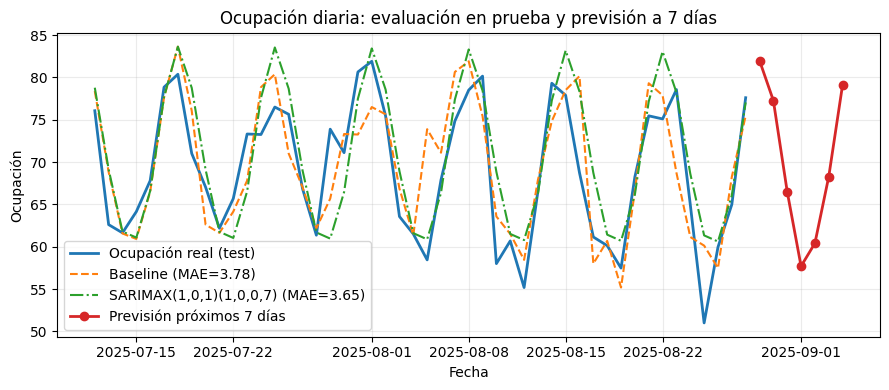

✔ Cuaderno ocupacion.ipynb ejecutado correctamente


In [ ]:
# ===================== CELDA 3: GRÁFICO Y COMPROBACIONES =====================
# Fechas de los 7 días futuros: empiezan el día siguiente a la última fecha conocida
fechas_7d = pd.date_range(fechas.iloc[-1] + pd.Timedelta(days=1), periods=7, freq="D")

fig, ax = plt.subplots(figsize=(9, 4))   # Crea figura y ejes de 9x4 pulgadas
ax.plot(fechas_test, test_y, label="Ocupación real (test)", linewidth=2)            # Línea de valores reales
ax.plot(fechas_test, pred_baseline, "--", label=f"Baseline (MAE={mae_baseline:.2f})")  # Baseline discontinuo
ax.plot(fechas_test, pred_sarimax, "-.", label=f"{nombre_m1} (MAE={mae_sarimax:.2f})")  # Modelo 1 punto-raya
ax.plot(fechas_7d, prev_7d, "o-", label="Previsión próximos 7 días", linewidth=2)    # Previsión futura con marcadores
ax.set_title("Ocupación diaria: evaluación en prueba y previsión a 7 días")   # Título
ax.set_xlabel("Fecha")                   # Etiqueta eje X
ax.set_ylabel("Ocupación")               # Etiqueta eje Y
ax.legend()                              # Muestra la leyenda
ax.grid(alpha=0.25)                      # Rejilla suave
plt.tight_layout()                       # Ajusta márgenes para que nada se corte
plt.show()                               # Dibuja el gráfico

# Comprobaciones mínimas: hay 7 previsiones y el MAE no es negativo
assert len(prev_7d) == 7 and mae_baseline >= 0
print("✔ Cuaderno ocupacion.ipynb ejecutado correctamente")